# Learning MACE on rMD17 ethanol

This notebook walks through the study of this repository step by step: what the data are, how the DFT labels
are made with ORCA, what MACE does with them, how well it learns, and whether the potential gives sound molecular
dynamics. The heavy calculations (training, 50 ps of MD, ORCA on many frames) are done by the scripts in
`scripts/`; here we load their results and repeat small parts of them live.

| | Section | What you learn |
| --- | --- | --- |
| 1 | [The paper and the target numbers](#1) | which result is reproduced |
| 2 | [The data](#2) | energies, forces, units, and why at most 1000 configurations |
| 3 | [DFT labels with ORCA](#3) | an ORCA input, and the check of the published labels |
| 4 | [Inside MACE](#4) | atomic energies, cutoff and radial basis, symmetry, descriptors |
| 5 | [Training](#5) | the training command and what the loss curve tells |
| 6 | [Test errors compared with the paper](#6) | the reproduction itself |
| 7 | [Molecular dynamics with MACE](#7) | running MD, energy conservation, torsions |
| 8 | [Checking MACE frames with ORCA](#8) | accuracy away from the training data |
| 9 | [Exercises](#9) | things to try next |

Run the cells from the top. The notebook expects the results of `run_all.sh` (or of the single steps); the data
download of step 1 is needed for section 2.

In [1]:
import csv
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np

# torch prints a long warning about checkpoint loading each time a model is read; it does not affect the results
warnings.filterwarnings('ignore', message='Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD')
# ASE announces a renamed function in a later version; the call used here works the same
warnings.filterwarnings('ignore', category=DeprecationWarning)

# the scripts folder holds the shared style and the ORCA driver
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'scripts'))
from mlip_style import (ACCENT_COLORS, DATA_DIR, ELEMENT_COLORS, FIGURE_DIR, MACE_COLOR, MODEL_DIR, ORCA_DIR,
                        PAPER_COLOR, PAPER_ETHANOL, REFERENCE_COLOR, RESULTS_DIR, WORK_DIR)

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display

print('project folder:', ROOT.name)

project folder: mace-rmd17-ethanol


<a id="1"></a>
## 1. The paper and the target numbers

**Batatia, Kovács, Simm, Ortner and Csányi, "MACE: Higher order equivariant message passing neural networks for
fast and accurate force fields", NeurIPS 2022**, [doi:10.48550/arXiv.2206.07697](https://doi.org/10.48550/arXiv.2206.07697).

Table 1 of the paper gives the mean absolute errors (MAE) of MACE on the revised MD17 dataset. For ethanol:

| training configurations | energy MAE (meV) | force MAE (meV/Å) |
| --- | --- | --- |
| 1000 (950 training + 50 validation) | 0.4 | 2.1 |
| 50 | 6.7 | 32.6 |

The energy MAE is per molecule (nine atoms), the force MAE per Cartesian component. The data are from
**Christensen and von Lilienfeld, Mach. Learn.: Sci. Technol. 1, 045018 (2020)**,
[doi:10.1088/2632-2153/abba6f](https://doi.org/10.1088/2632-2153/abba6f).

The paper trained on a data-center GPU (NVIDIA A100) with 256 feature channels. Here everything runs on a laptop
CPU, with 64 channels: the question is how close a laptop gets.

<a id="2"></a>
## 2. The data

rMD17 took 100 000 configurations from the original MD17 trajectories (ab initio MD at 500 K, time step 0.5 fs)
and recomputed their energies and forces with PBE/def2-SVP in ORCA, with tight settings so that the labels carry
almost no numerical noise. The file of each molecule is a NumPy archive.

In [2]:
KCAL_PER_MOL_TO_EV = 4.184 / 96.48533212   # 1 kcal/mol in eV

dataset = np.load(WORK_DIR / 'download' / 'rmd17' / 'npz_data' / 'rmd17_ethanol.npz')
for key in dataset.files:
    print(f'{key:16s} shape {str(dataset[key].shape):16s} dtype {dataset[key].dtype}')

energies = dataset['energies'] * KCAL_PER_MOL_TO_EV          # eV, one per configuration
forces = dataset['forces'] * KCAL_PER_MOL_TO_EV              # eV/Å, configurations x 9 atoms x 3
print()
print('nuclear charges:', dataset['nuclear_charges'], '-> C, C, O and six H')
print(f'energy: mean {energies.mean():.3f} eV, spread (std) {energies.std() * 1000:.0f} meV')
print(f'force components: std {forces.std():.3f} eV/Å, largest |F| {np.abs(forces).max():.2f} eV/Å')

nuclear_charges  shape (9,)             dtype uint8
coords           shape (100000, 9, 3)   dtype float64
energies         shape (100000,)        dtype float64
forces           shape (100000, 9, 3)   dtype float64
old_indices      shape (100000,)        dtype int64
old_energies     shape (100000,)        dtype float64


old_forces       shape (100000, 9, 3)   dtype float64



nuclear charges: [6 6 8 1 1 1 1 1 1] -> C, C, O and six H
energy: mean -4209.617 eV, spread (std) 186 meV
force components: std 1.193 eV/Å, largest |F| 9.34 eV/Å


The total energy is about −4209 eV, but only its **variation** of a few hundred meV between configurations matters
for the dynamics. A model that gets 0.4 meV right on top of −4209 eV must resolve 1 part in 10<sup>7</sup>; this is
why MACE adds the energies of the isolated atoms (E0s) as a fixed baseline and learns only the rest.

### Why not train on more than 1000 configurations?

The readme of rMD17 warns not to train on more than 1000 samples: the configurations come from one trajectory, so
neighboring ones are almost copies of each other. The `old_indices` key gives the position of each configuration
in the original trajectory, so we can sort them in time and measure how fast the energy forgets its past.

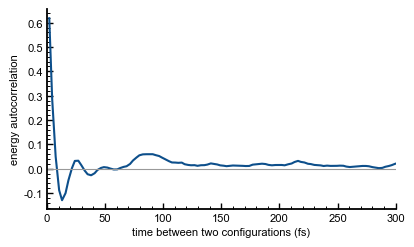

median spacing of the 100 000 configurations: 2.0 fs


In [3]:
# sort the configurations in the order of the original trajectory (one index = one MD step of 0.5 fs)
order = np.argsort(dataset['old_indices'])
time_fs = dataset['old_indices'][order] * 0.5
energy_series = energies[order] - energies.mean()

# correlation of the energy at two times, collected by their time difference
lag_fs = []
correlation = []
for shift in range(1, 400):
    gaps = time_fs[shift:] - time_fs[:-shift]
    products = energy_series[shift:] * energy_series[:-shift]
    lag_fs.append(np.median(gaps))
    correlation.append(products.mean() / energy_series.var())

fig, ax = plt.subplots(figsize=(4.5, 2.6))
ax.plot(lag_fs, correlation, color=MACE_COLOR)
ax.axhline(0, color='0.6', lw=0.8)
ax.set_xlabel('time between two configurations (fs)')
ax.set_ylabel('energy autocorrelation')
ax.set_xlim(0, 300)
plt.show()
print(f'median spacing of the 100 000 configurations: {np.median(np.diff(time_fs)):.1f} fs')

The energy oscillates with the fastest vibrations (C–H and O–H stretches, about 10 fs) and the correlation decays
within a few hundred femtoseconds. The whole trajectory is a few hundred picoseconds long, so it holds only some
thousands of really independent configurations: a test set that is close in time to the training set would
measure memory, not learning. With 1000 random training configurations, the test configurations are still
reasonably independent.

The training and test sets of **split 1** are written by `scripts/step1_prepare_rmd17.py` as extended-XYZ files,
with the keys `REF_energy` and `REF_forces` that MACE reads:

1000 training and 1000 test configurations
first training configuration: C2H6O {'REF_energy': np.float64(-4209.783867156023), 'rmd17_index': np.int64(78)}
Properties=species:S:1:pos:R:3:REF_forces:R:3 REF_energy=-4209.783867156023 rmd17_index=78 pbc="F F F" ...


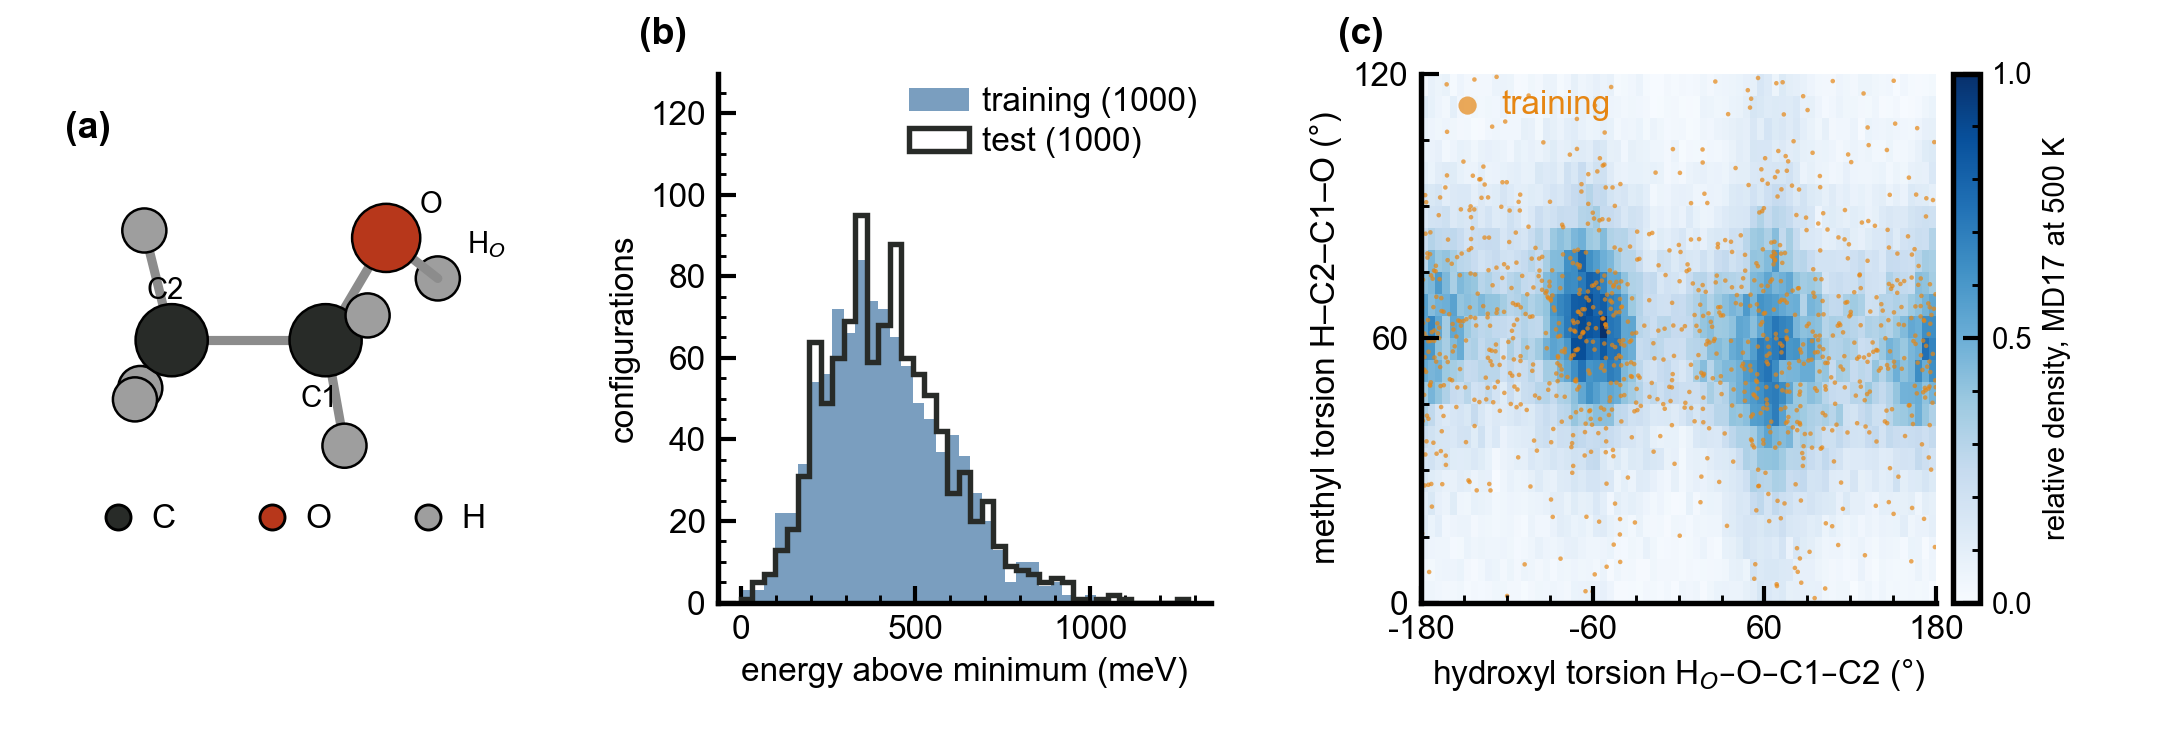

In [4]:
from ase.io import read

train = read(DATA_DIR / 'ethanol_train_N1000.xyz', ':')
test = read(DATA_DIR / 'ethanol_test.xyz', ':')
print(len(train), 'training and', len(test), 'test configurations')
print('first training configuration:', train[0].get_chemical_formula(), train[0].info)
print((DATA_DIR / 'ethanol_train_N50.xyz').read_text().splitlines()[1][:200], '...')
display(Image(FIGURE_DIR / 'Figure_1_data.png', width=900))

Figure 1: (a) ethanol and the atoms of its two torsions; (b) the energies of the training and test sets, which
cover the same range; (c) the two torsions over the whole 500 K trajectory (blue) and the 1000 training
configurations (orange). The hydroxyl hydrogen visits the two gauche positions (±60°) more often than trans
(180°). Because both sets are random draws from the same trajectory, the test set measures *interpolation*
within the visited configurations, not extrapolation.

<a id="3"></a>
## 3. DFT labels with ORCA

Every label of rMD17 is one ORCA calculation: the energy of one configuration and its gradient. The paper of
the dataset (section 4.3.1) used ORCA 4.0.1 with `PBE def2-SVP`, RI for the Coulomb integrals, `VeryTightSCF`
and `Grid7 NoFinalGrid`. ORCA 5 has no `GridN` keywords any more; its densest standard grid is `DefGrid3`.
Here is the input of one configuration, with every keyword explained:

In [5]:
print((ROOT / 'orca' / 'example_ethanol_single_point.inp').read_text())

# ORCA input: energy and forces of one ethanol configuration at the level of theory of rMD17.
#
# Lines starting with # are comments. The line starting with ! holds the keywords:
#   PBE            exchange-correlation functional (a GGA), Perdew, Burke and Ernzerhof (1996)
#   def2-SVP       basis set, split valence with polarization functions (Weigend and Ahlrichs, 2005)
#   def2/J         auxiliary basis for the RI approximation of the Coulomb integrals (default for GGAs)
#   VeryTightSCF   SCF converged to 1e-9 Hartree, so that the forces carry no convergence noise
#   DefGrid3       the densest standard integration grid of ORCA 5 (rMD17 used Grid7 NoFinalGrid of ORCA 4)
#   EnGrad         compute the energy and its gradient; the gradient is written to <name>.engrad
#
# The geometry follows "* xyz charge multiplicity": neutral (0), closed shell (singlet, 1), positions in Å.
# This configuration is index 4823 of the rMD17 ethanol data (test set of split 1).
#
# Run:  bash orca/run_or

ORCA writes the energy and the gradient to a `.engrad` file, in Hartree and Hartree/Bohr. The force is minus the
gradient. `scripts/orca_tools.py` reads it and converts to eV and eV/Å:

In [6]:
from orca_tools import read_engrad

engrad_file = ROOT / 'orca' / 'example_ethanol_single_point.engrad'
if engrad_file.exists():
    orca_energy, orca_forces = read_engrad(engrad_file, 9)
    index = 4823   # the rMD17 index of this configuration
    print(f'ORCA 5   energy {orca_energy:.5f} eV')
    print(f'rMD17    energy {energies[index]:.5f} eV')
    print(f'largest force difference {np.abs(orca_forces - forces[index]).max() * 1000:.3f} meV/Å')
else:
    print('run first:  bash orca/run_orca.sh orca/example_ethanol_single_point.inp')

ORCA 5   energy -4209.34481 eV
rMD17    energy -4209.34471 eV
largest force difference 0.922 meV/Å


To run ORCA from here, set `RUN_ORCA = True` (about 10–30 s). ORCA has to be called with its full path.

In [7]:
import os

RUN_ORCA = False
# full path of the orca executable: from the environment, or write it here
os.environ.setdefault('ORCA_EXE', '/full/path/to/orca')

if RUN_ORCA:
    from orca_tools import run_single_point
    atoms = test[0]
    start = time.time()
    energy, orca_forces = run_single_point(atoms.get_chemical_symbols(), atoms.positions,
                                           WORK_DIR / 'notebook_orca_test')
    print(f'{time.time() - start:.0f} s; energy difference to rMD17 '
          f"{(energy - atoms.info['REF_energy']) * 1000:.3f} meV")

`scripts/step2_check_labels_orca.py` recomputed 12 test configurations in the same way (all inputs and outputs
are in `orca/calculations/rmd17_label_check/`):

{
  "orca_method": "PBE def2-SVP def2/J VeryTightSCF DefGrid3",
  "n_configurations": 12,
  "mean_energy_offset_meV": -0.10649303862919623,
  "relative_energy_mae_meV": 0.011336589295751764,
  "force_mae_meV_per_A": 0.1245600863753142,
  "force_max_abs_difference_meV_per_A": 1.0767611584796555
}


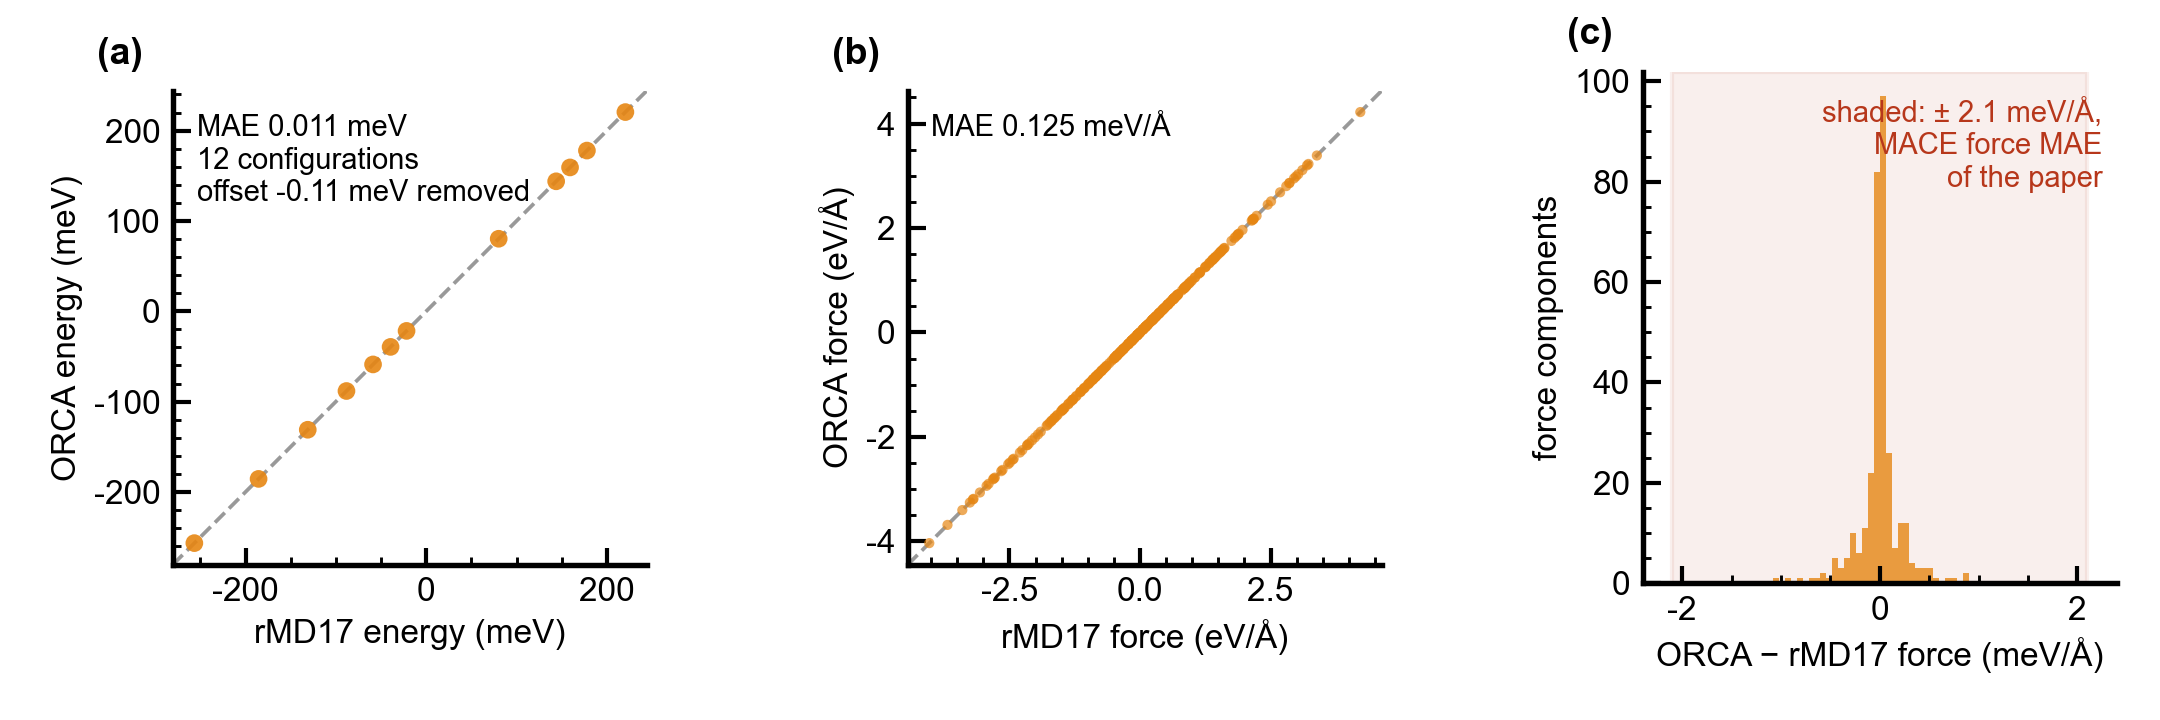

In [8]:
print(json.dumps(json.loads((RESULTS_DIR / 'orca_label_check.json').read_text()), indent=2))
display(Image(FIGURE_DIR / 'Figure_2_orca_check.png', width=900))

ORCA 5 with `DefGrid3` reproduces the published forces to about 0.1 meV/Å, twenty times below the best MACE
error of the paper (shaded in panel c). The constant energy offset of −0.1 meV comes from the different
integration grid; it does not matter, because a constant shifts all energies equally and changes no force. The
reference data are therefore reproducible, and we can use the same ORCA settings later to check configurations
that MACE generated itself.

<a id="4"></a>
## 4. Inside MACE

MACE writes the energy of a configuration as a sum of atomic energies,

$$E = \sum_i \left( E_0^{Z_i} + \varepsilon_i \right),$$

where $E_0^{Z}$ is a fixed energy for each element (the E0s) and $\varepsilon_i$ depends on the neighbors of atom
$i$ within the cutoff $r_\mathrm{cut} = 5$ Å. The forces are the exact derivatives $\mathbf{F}_i = -\partial
E / \partial \mathbf{r}_i$, computed by automatic differentiation; the energy is therefore conserved in MD.

Four ideas make MACE accurate with few data:

1. **Radial basis.** Distances enter through 8 Bessel functions multiplied by a smooth cutoff, so the energy
   changes smoothly when an atom leaves the cutoff sphere.
2. **Equivariance.** Directions enter through spherical harmonics up to $l_\mathrm{max} = 3$. Features carry the
   symmetry of vectors and tensors, so rotating the molecule rotates the forces and leaves the energy unchanged,
   exactly and without learning it.
3. **Higher body order.** Each layer forms products of neighbor features up to correlation order $\nu = 3$, which
   gives four-body terms (an atom and three neighbors: torsions) in one layer.
4. **Two layers of message passing.** The second layer sees what the first learned about the neighbors, which
   extends the receptive field to 2 × 5 Å.

### Neighbors within the cutoff

In [9]:
from ase.neighborlist import neighbor_list

R_CUT = 5.0   # cutoff radius (Å) of the paper and of this study
first_atoms, second_atoms = neighbor_list('ij', train[0], R_CUT)
neighbors = np.bincount(first_atoms, minlength=len(train[0]))
print('neighbors of each atom within 5 Å:', neighbors)
print('largest distance in the molecule: %.2f Å' % train[0].get_all_distances().max())

neighbors of each atom within 5 Å: [8 8 8 8 8 8 8 8 8]
largest distance in the molecule: 3.97 Å


Ethanol is smaller than the cutoff: every atom sees all eight others. (This is the "Average number of neighbors:
8.0" in the training log.) For a molecule this small, MACE is not "local" at all; the cutoff matters for larger
molecules, liquids and surfaces.

### The radial basis

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


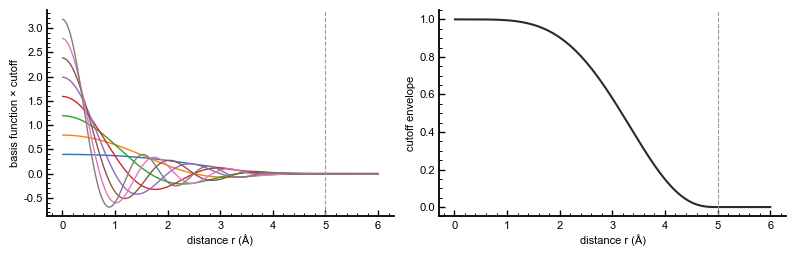

In [10]:
import torch
from mace.modules.radial import BesselBasis, PolynomialCutoff

distances = torch.linspace(0.01, 6.0, 400).unsqueeze(-1)
bessel = BesselBasis(r_max=R_CUT, num_basis=8)(distances)          # 8 functions sin(n pi r / r_cut) / r
cutoff = PolynomialCutoff(r_max=R_CUT, p=5)(distances)              # smooth envelope, zero at r_cut

fig, axes = plt.subplots(1, 2, figsize=(8, 2.6))
for n in range(8):
    axes[0].plot(distances[:, 0], (bessel[:, n] * cutoff[:, 0]).numpy(), lw=1.0)
axes[0].set_xlabel('distance r (Å)')
axes[0].set_ylabel('basis function × cutoff')
axes[1].plot(distances[:, 0], cutoff[:, 0].numpy(), color=REFERENCE_COLOR)
axes[1].set_xlabel('distance r (Å)')
axes[1].set_ylabel('cutoff envelope')
for ax in axes:
    ax.axvline(R_CUT, color='0.6', ls='--', lw=0.8)
plt.tight_layout()
plt.show()

The network learns how to combine these eight functions for each pair of elements. Every function goes smoothly
to zero at 5 Å, with zero slope and curvature: no force jumps when atoms cross the cutoff.

### Symmetry, tested on the trained model

We rotate a test configuration by a random rotation. The energy must stay the same and the forces must rotate
with the molecule.

In [11]:
from mace.calculators import MACECalculator
from scipy.spatial.transform import Rotation

model_path = MODEL_DIR / 'ethanol_N1000_stagetwo.model'
if not model_path.exists():
    model_path = MODEL_DIR / 'ethanol_N50_stagetwo.model'
calculator = MACECalculator(model_paths=str(model_path), device='cpu', default_dtype='float32')
print('model:', model_path.name)

atoms = test[0].copy()
atoms.calc = calculator
energy = atoms.get_potential_energy()
model_forces = atoms.get_forces()

rotation = Rotation.random(random_state=1).as_matrix()
rotated = atoms.copy()
rotated.positions = atoms.positions @ rotation.T
rotated.calc = calculator
print(f'energy change on rotation: {(rotated.get_potential_energy() - energy) * 1000:.4f} meV')
print(f'largest difference between rotated forces and forces of the rotated molecule: '
      f'{np.abs(rotated.get_forces() - model_forces @ rotation.T).max() * 1000:.4f} meV/Å')

model: ethanol_N1000_stagetwo.model


energy change on rotation: 0.0000 meV
largest difference between rotated forces and forces of the rotated molecule: 0.0038 meV/Å


Both differences are at the level of float32 rounding. The symmetry is built into the architecture, so none of
the 1000 training configurations is spent on learning it.

### What the model has learned: atomic descriptors

The last-layer features of each atom form a descriptor of its chemical environment. Projected on their two main
directions (a principal component analysis), the six hydrogens of ethanol fall into three groups without ever
being told their chemistry: methyl, methylene and hydroxyl.

descriptor of one atom: 128 numbers


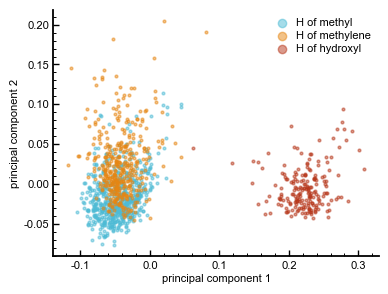

In [12]:
from step1_prepare_rmd17 import torsion_atoms

oxygen, carbon_1, carbon_2, hydroxyl_hydrogen, methyl_hydrogens = torsion_atoms(test[0].numbers, test[0].positions)
groups = {'C2 (methyl C)': [carbon_2], 'C1 (methylene C)': [carbon_1], 'O': [oxygen],
          'H of methyl': methyl_hydrogens, 'H of hydroxyl': [hydroxyl_hydrogen]}
groups['H of methylene'] = []
for i in range(9):
    # the two hydrogens on C1 are the ones that are neither methyl nor hydroxyl hydrogens
    if test[0].numbers[i] == 1 and i not in methyl_hydrogens and i != hydroxyl_hydrogen:
        groups['H of methylene'].append(i)

descriptors = []
for atoms in test[:200]:
    descriptors.append(calculator.get_descriptors(atoms, invariants_only=True))
descriptors = np.array(descriptors)                    # configurations x atoms x features
print('descriptor of one atom:', descriptors.shape[-1], 'numbers')

# principal components of the hydrogen descriptors only
hydrogens = [i for i in range(9) if test[0].numbers[i] == 1]
hydrogen_descriptors = descriptors[:, hydrogens, :].reshape(-1, descriptors.shape[-1])
mean = hydrogen_descriptors.mean(axis=0)
_, _, components = np.linalg.svd(hydrogen_descriptors - mean, full_matrices=False)

fig, ax = plt.subplots(figsize=(4.2, 3.2))
colors = {'H of methyl': ACCENT_COLORS[0], 'H of methylene': ACCENT_COLORS[1], 'H of hydroxyl': ACCENT_COLORS[3]}
for name, color in colors.items():
    projected = (descriptors[:, groups[name], :].reshape(-1, descriptors.shape[-1]) - mean) @ components[:2].T
    ax.scatter(projected[:, 0], projected[:, 1], s=4, alpha=0.5, color=color, label=name)
ax.set_xlabel('principal component 1')
ax.set_ylabel('principal component 2')
ax.legend(markerscale=3)
plt.show()

<a id="5"></a>
## 5. Training

`scripts/step3_train_mace.sh` calls `mace_run_train` with the settings of Appendix A.5 of the paper. The
differences are the smaller model and the second training stage:

| setting | paper | here |
| --- | --- | --- |
| hardware | NVIDIA A100 | laptop CPU (4 cores) |
| channels, message equivariance | 256, up to L = 3 | 64, L = 1 |
| interactions, correlation order, l<sub>max</sub> | 2, 3, 3 | 2, 3, 3 |
| cutoff, radial basis | 5 Å, 8 Bessel, p = 5 | same |
| loss weights energy : forces | 1 : 1000 | 1 : 1000, then 1000 : 100 for the last 40 % (stage two) |
| optimizer | AMSGrad, lr 0.01, batch 5, plateau 50 / 0.8, EMA 0.99 | same |
| precision | float32 | float32 |
| epochs | not given (2–6 h on A100) | 1000 (n = 50), 250 (n = 1000) |

The history of every evaluation is in `work/mace/results/<name>_train.txt`, one JSON line each:

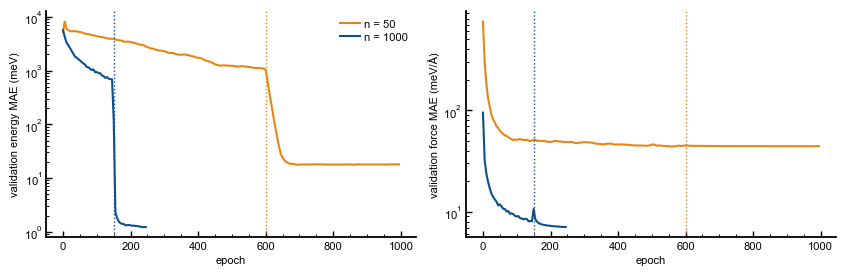

In [13]:
def read_history(name):
    # epochs and validation errors (meV, meV/Å) of one training run
    path = WORK_DIR / 'mace' / 'results' / f'{name}_run-123_train.txt'
    epochs, energy_mae, force_mae = [], [], []
    for line in path.read_text().splitlines():
        entry = json.loads(line)
        if entry.get('mode') == 'eval' and entry.get('epoch') is not None:
            epochs.append(entry['epoch'])
            energy_mae.append(entry['mae_e'] * 1000)
            force_mae.append(entry['mae_f'] * 1000)
    return np.array(epochs), np.array(energy_mae), np.array(force_mae)


fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.8))
for n_train, color, stage_two in [(50, ACCENT_COLORS[1], 600), (1000, MACE_COLOR, 150)]:
    try:
        epochs, energy_mae, force_mae = read_history(f'ethanol_N{n_train}')
    except FileNotFoundError:
        continue
    axes[0].plot(epochs, energy_mae, color=color, label=f'n = {n_train}')
    axes[1].plot(epochs, force_mae, color=color, label=f'n = {n_train}')
    for ax in axes:
        ax.axvline(stage_two, color=color, ls=':', lw=1)
for ax, label in zip(axes, ['validation energy MAE (meV)', 'validation force MAE (meV/Å)']):
    ax.set_yscale('log')
    ax.set_xlabel('epoch')
    ax.set_ylabel(label)
axes[0].legend()
plt.tight_layout()
plt.show()

The energy error **rises** to several eV at the start, although the untrained model was within about 0.2 eV:
forces do not change when a constant is added to the energy, and with the force weight of 1000 the optimizer moves
the energy constant freely while it fits the forces. When stage two starts (dotted lines) the energy weight goes
up to 1000 and the offset is removed within a few epochs, while the force error keeps falling. This is why the
second stage was added here; with 50 configurations an epoch has only nine optimizer steps and the first stage
alone did not remove the offset.

<a id="6"></a>
## 6. Test errors compared with the paper

`scripts/step4_test_errors.py` predicts the 1000 test configurations of split 1 with each model:

     n   energy MAE (meV)    paper   force MAE (meV/Å)    paper
    50              11.96      6.7               40.01     32.6
  1000               1.37      0.4                7.88      2.1


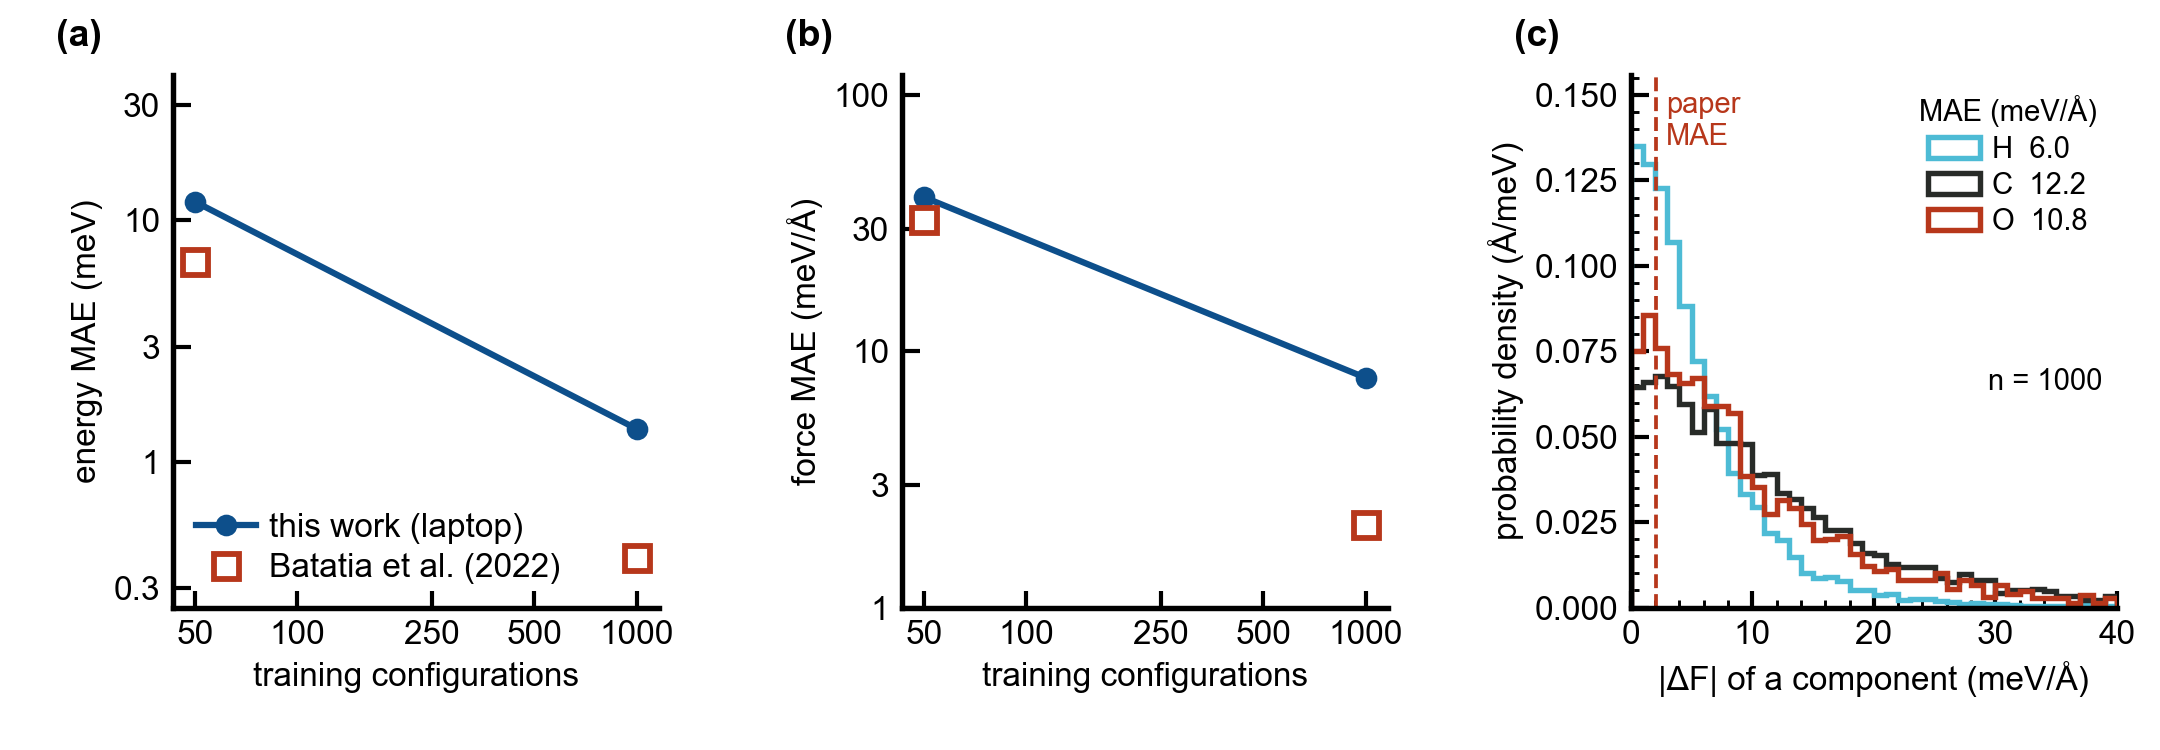

In [14]:
with open(RESULTS_DIR / 'test_errors.csv') as table:
    rows = list(csv.DictReader(table))
print(f"{'n':>6} {'energy MAE (meV)':>18} {'paper':>8} {'force MAE (meV/Å)':>19} {'paper':>8}")
for row in rows:
    n_train = int(row['n_train'])
    paper = PAPER_ETHANOL.get(n_train, {'energy_mae_meV': float('nan'), 'force_mae_meV_per_A': float('nan')})
    print(f"{n_train:>6} {float(row['energy_mae_meV']):>18.2f} {paper['energy_mae_meV']:>8} "
          f"{float(row['force_mae_meV_per_A']):>19.2f} {paper['force_mae_meV_per_A']:>8}")
display(Image(FIGURE_DIR / 'Figure_3_accuracy.png', width=900))

How to read these numbers:

- **n = 50.** 12.0 meV and 40.0 meV/Å against 6.7 and 32.6 in the paper: the force error is within 25 % of the
  paper. With 50 configurations the error is set by the data, and the smaller model costs little.
- **n = 1000.** 1.4 meV and 7.9 meV/Å against 0.4 and 2.1: about four times the paper. Here the data are no
  longer the limit, the model and the training are: 64 instead of 256 channels, messages up to L = 1 instead of
  L = 3, and 250 epochs on a CPU (3.4 h) instead of a training of several hours on an A100.
- **Slope.** From 50 to 1000 configurations the force error falls 5-fold here and 16-fold in the paper. A larger
  model keeps learning from more data; a small one flattens out earlier.
- **Panel c.** Hydrogen forces are learned best (6.0 meV/Å), carbon and oxygen worst (12.2 and 10.8 meV/Å). Heavy
  atoms sit in the middle of the molecule and feel more neighbors, so their forces are harder to learn. The
  distributions have long tails, which is why the RMSE in `results/test_errors.csv` is about 1.8 times the MAE.

Exercise 1 below asks how much of the gap a larger model removes.

<a id="7"></a>
## 7. Molecular dynamics with MACE

A trained MACE model is an ASE calculator, so any ASE dynamics works. Here are 2 ps without a thermostat (NVE),
started from a test configuration with velocities for 500 K. If the forces are the exact derivative of a smooth
energy, the total energy stays constant while potential and kinetic energy exchange.

7 MD steps per second on this computer


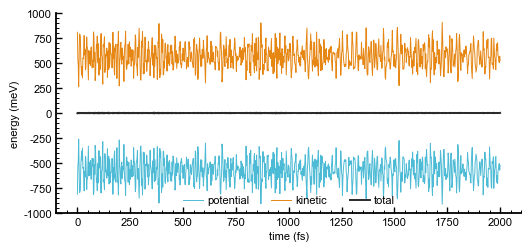

total energy: std 1.39 meV, kinetic energy std 114 meV


In [15]:
from ase import units
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution, Stationary, ZeroRotation
from ase.md.verlet import VelocityVerlet

atoms = test[0].copy()
atoms.calc = calculator
MaxwellBoltzmannDistribution(atoms, temperature_K=500, rng=np.random.default_rng(3))
Stationary(atoms)
ZeroRotation(atoms)

dynamics = VelocityVerlet(atoms, 0.5 * units.fs)
record = {'time_fs': [], 'potential': [], 'kinetic': []}
frames = []     # the configurations, for the viewer below


def save_energies():
    # called by ASE every 4 steps (2 fs)
    record['time_fs'].append(dynamics.get_number_of_steps() * 0.5)
    record['potential'].append(atoms.get_potential_energy())
    record['kinetic'].append(atoms.get_kinetic_energy())
    frames.append(atoms.copy())


dynamics.attach(save_energies, interval=4)
start = time.time()
dynamics.run(4000)      # 2 ps
print(f'{4000 / (time.time() - start):.0f} MD steps per second on this computer')

potential = np.array(record['potential'])
kinetic = np.array(record['kinetic'])
total = potential + kinetic
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(record['time_fs'], (potential - total[0]) * 1000, lw=0.7, color=ACCENT_COLORS[0], label='potential')
ax.plot(record['time_fs'], kinetic * 1000, lw=0.7, color=ACCENT_COLORS[1], label='kinetic')
ax.plot(record['time_fs'], (total - total[0]) * 1000, lw=1.4, color=REFERENCE_COLOR, label='total')
ax.set_xlabel('time (fs)')
ax.set_ylabel('energy (meV)')
ax.legend(ncol=3)
plt.show()
print(f'total energy: std {total.std() * 1000:.2f} meV, kinetic energy std {kinetic.std() * 1000:.0f} meV')

### Watching the molecule

The curves above are numbers; it helps to see the motion itself. [nglview](https://github.com/nglviewer/nglview)
shows the 2 ps just computed as a 3D movie: drag to rotate, scroll to zoom, and use the play button. The C-H and O-H
bonds vibrate every 10 fs, the C-C-O frame bends more slowly, and the hydroxyl and methyl groups rotate.

The viewer works only in a running Jupyter session. On GitHub the output of these cells stays empty; the recorded
animation further below shows the same motion there.

In [16]:
import nglview

# one frame every 2 fs of the 2 ps run above
view = nglview.show_asetraj(frames)
view.clear_representations()
view.add_ball_and_stick()
view

NGLWidget(max_frame=1000)

In [17]:
from ase.io import read

# the 50 ps run of scripts/step5_md_mace.py, if it has been run: every 4th saved frame (20 fs apart)
trajectory_path = WORK_DIR / 'md' / 'nvt_500K.traj'
if trajectory_path.exists():
    long_run = read(trajectory_path, '::4')
    print(f'{len(long_run)} frames of the 500 K run')
    long_view = nglview.show_asetraj(long_run)
    long_view.clear_representations()
    long_view.add_ball_and_stick()
    display(long_view)
else:
    print('run scripts/step5_md_mace.py first to see the 50 ps run')

2501 frames of the 500 K run


NGLWidget(max_frame=2500)

Below are 2 ps of the 500 K run of step 5, recorded with `python scripts/make_figures.py movie`. The molecule is
drawn in the frame of its C-C-O atoms, so that it does not tumble, and the hydroxyl hydrogen is orange. On the
right, the hydroxyl torsion H-O-C1-C2 on 0 ... 360°: trans at 180°, the two gauche minima at 60° and 300°. In
this piece the molecule leaves the gauche minimum at 300°, crosses trans and settles in the gauche minimum at 60°.

<img src="../docs/images/md_ethanol.gif" width="720" alt="Ethanol in the MACE run at 500 K and its hydroxyl torsion">

`scripts/step5_md_mace.py` runs 50 ps at 500 K with a Langevin thermostat (the temperature of MD17) and then
10 ps NVE; `scripts/step6_check_md.py` compares the torsions with those of the original ab initio trajectory.

**A pitfall met in this study.** The first run used ASE's `Langevin(..., fixcm=True)`, the default, and the
molecule settled at about 650 K instead of 500 K. To keep the center of mass at rest, that option takes the same share of
the net random momentum from every atom and then scales all kicks up by sqrt(N / (N - 1)). The correction is exact
only for atoms of equal mass; with hydrogen (1 u) next to carbon (12 u) and oxygen (16 u) in a 9-atom molecule the
temperature comes out wrong, and the ASE documentation now warns that the option is not correct for small systems. The script
uses `fixcm=False` with the constraint `FixCom()`, which gives 500 K. Always check the mean temperature of a
thermostatted run, especially for small systems.

{
  "md_frames_checked_with_orca": 20,
  "md_energy_offset_meV": -0.26289346496923827,
  "md_relative_energy_mae_meV": 0.9531787963169336,
  "md_force_mae_meV_per_A": 5.763511442273675,
  "nvt_mean_temperature_K": 501.4874575,
  "nvt_production_ps": 40.0,
  "trans_fraction_mace": 0.2715,
  "trans_fraction_md17": 0.29397,
  "nve_total_energy_std_meV": 1.2760773820936984,
  "nve_kinetic_energy_std_meV": 107.8061115162521,
  "nve_drift_meV_per_ps": 0.039834484020182914
}


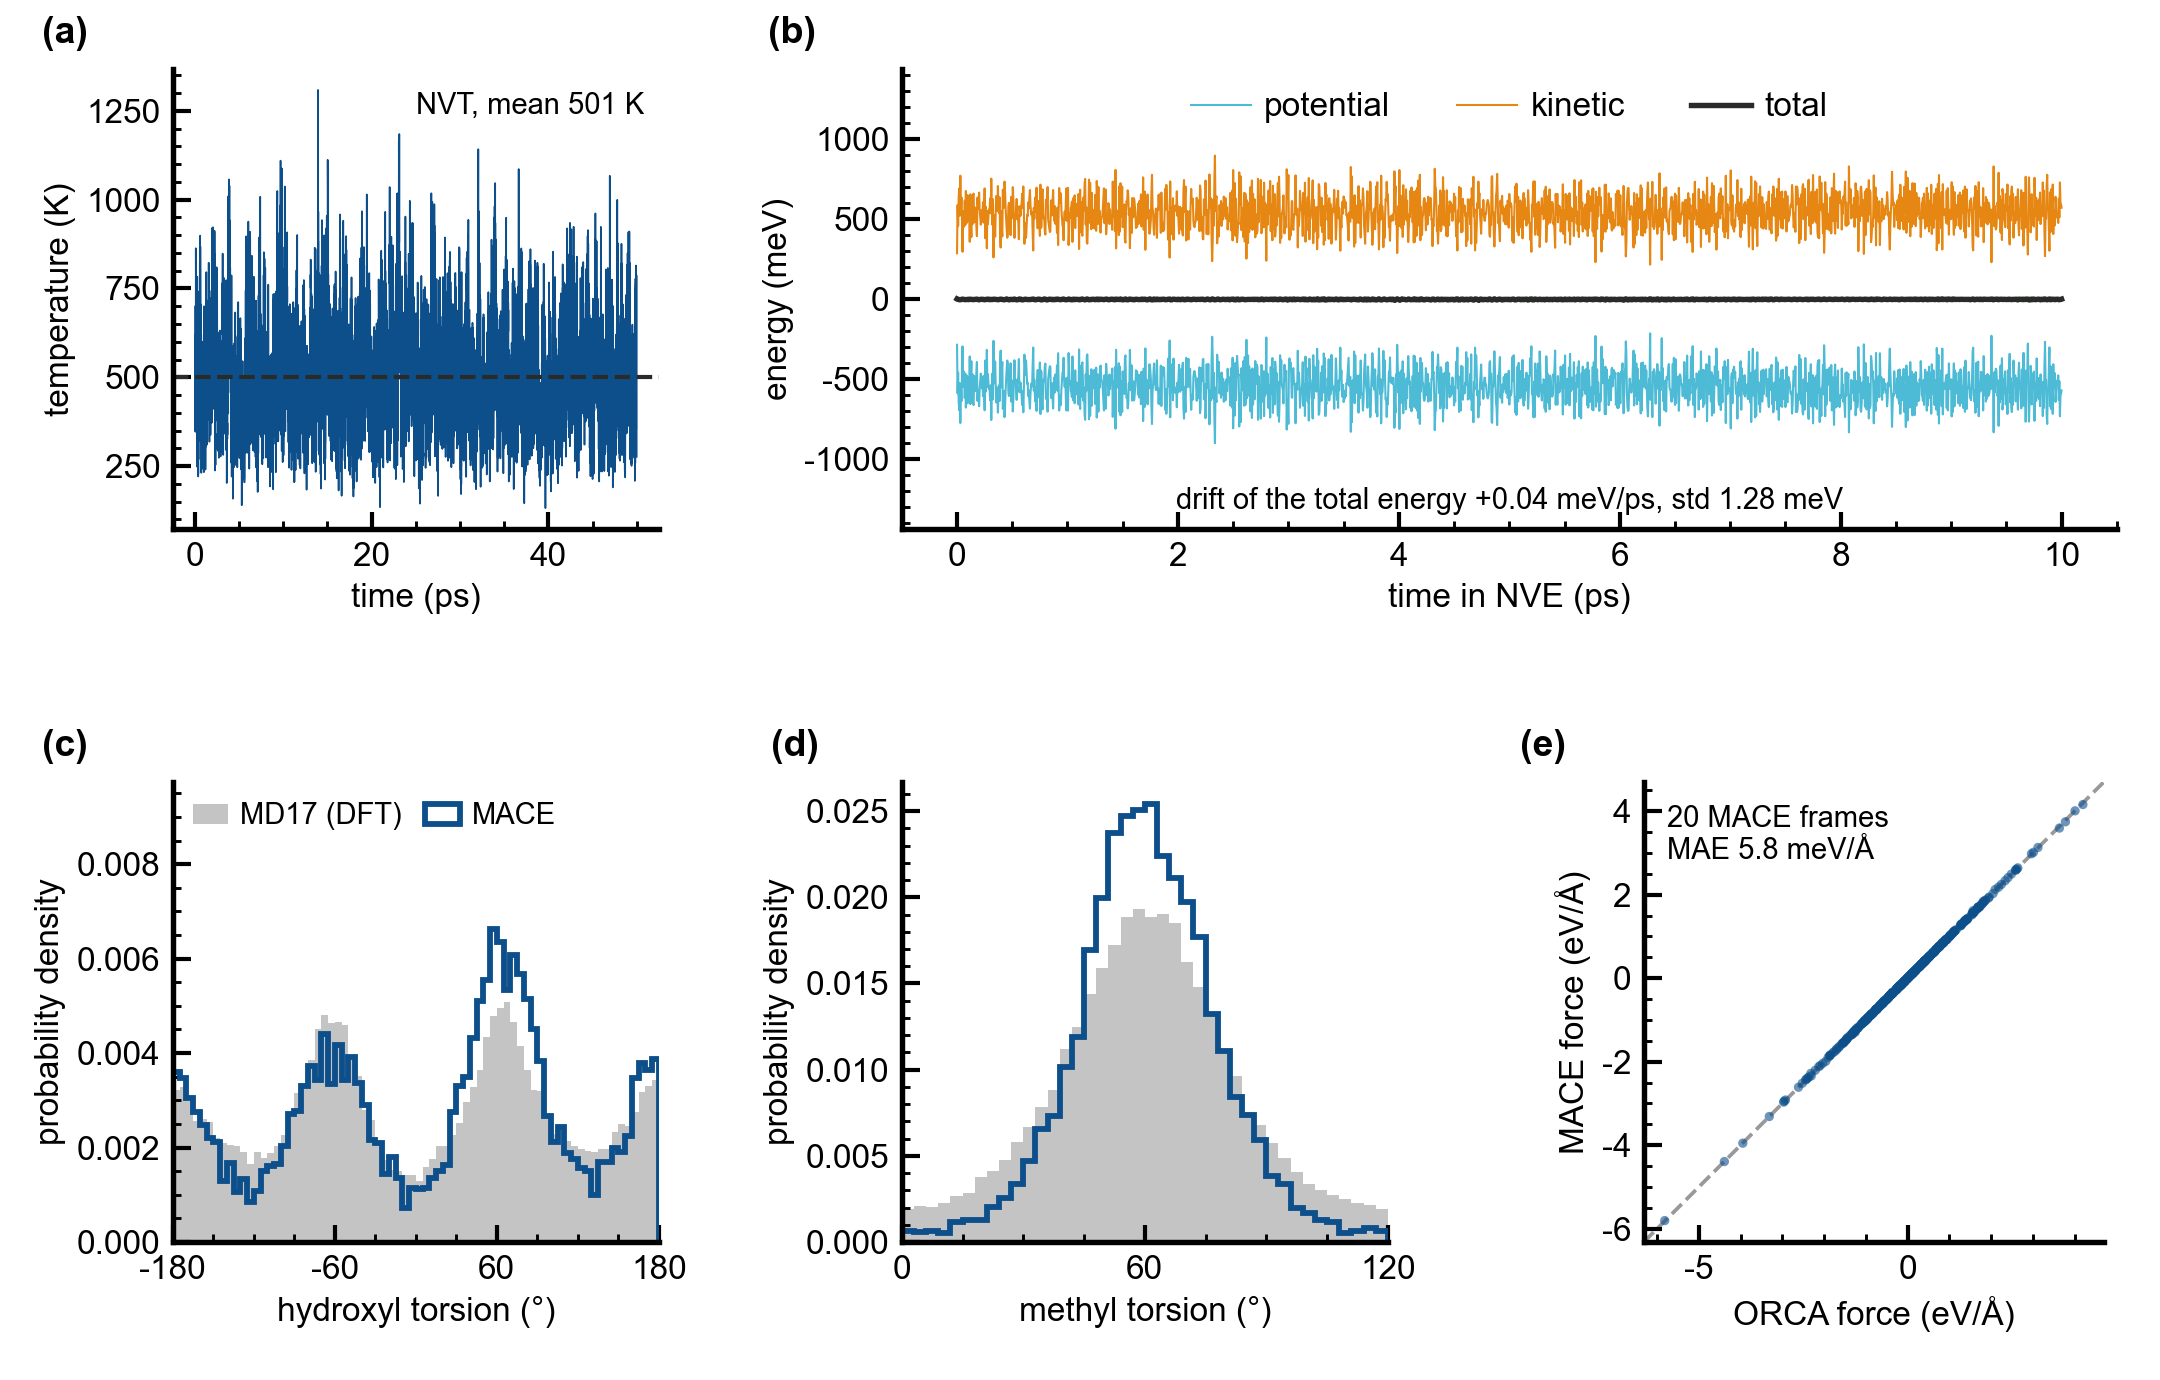

In [18]:
md_summary = json.loads((RESULTS_DIR / 'md_summary.json').read_text())
print(json.dumps(md_summary, indent=2))
display(Image(FIGURE_DIR / 'Figure_4_md.png', width=900))

What the run shows:

- **Temperature (a).** The mean is 501 K. A 9-atom molecule has only 24 degrees of freedom, so the instantaneous
  temperature swings mostly between 250 and 900 K; that is the physics of a small system, not noise of the model.
- **Energy conservation (b).** Over 10 ps the total energy fluctuates by 1.3 meV (standard deviation) and drifts
  by +0.04 meV/ps, while kinetic and potential energy exchange about 100 meV. The forces of MACE are the exact
  gradient of its energy, so the only error is that of the 0.5 fs time step.
- **Hydroxyl torsion (c).** MACE finds the trans (180°) and the two gauche (±60°) minima of the ab initio
  trajectory, with a trans fraction of 0.27 against 0.29. The two gauche peaks of MACE differ in height although
  they are mirror images: 40 ps holds about 130 jumps between the minima, too few for a converged
  histogram. The MD17 trajectory is much longer.
- **Methyl torsion (d).** The MACE distribution is narrower than that of MD17. Two causes are possible, and this
  study does not separate them: the MD17 trajectory was run with PBE+vdW-TS in FHI-aims, while the model learned
  the PBE/def2-SVP energies of rMD17, so the two methyl barriers need not agree; and the model may be stiffer than
  its reference. Exercise 6 tests this with ORCA.

<a id="8"></a>
## 8. Checking MACE frames with ORCA

A low test error says that MACE interpolates well *between the rMD17 configurations*. In MD, the model creates
its own configurations, and errors can push the dynamics into regions without training data, where they grow.
Recomputing frames of the MACE trajectory with ORCA (panel e of Figure 4, inputs and outputs in
`orca/calculations/mace_md_check/`) tests this directly: if the force error on these frames is close to the test
error, the dynamics stayed in the region that the model knows.

Result: on 20 frames of the MACE trajectory, the force MAE against ORCA is **5.8 meV/Å** and the relative
energy MAE 1.0 meV, close to (even below) the test errors of 7.9 meV/Å and 1.4 meV. At 500 K the dynamics stays
in the region of the training data.

This is also the first step of **active learning**: frames where MACE and DFT disagree would be added to the
training set, the model retrained, and the loop repeated.

<a id="9"></a>
## 9. Exercises

1. **Model size.** Train with `NUM_CHANNELS=128` or `MAX_L=2` (`scripts/step3_train_mace.sh`). How much do the
   errors fall, and how much longer does an epoch take?
2. **Learning curve.** Run `SIZES="100 250 500" bash scripts/step3_learning_curve.sh` and fit the slope of
   log(force MAE) against log(n). Christensen and von Lilienfeld (2020) explain why it should be a straight line.
3. **Energies only.** Set `--forces_weight=0` and train on 1000 configurations. The rMD17 paper found that
   forces improve the errors about 7-fold for the same number of configurations. Is this true for MACE?
4. **Other splits.** Prepare split 2 (`SPLIT = 2` in step 1) and retrain: how large is the spread between splits?
5. **Higher temperature.** Run the MD at 1000 K and recompute frames with ORCA. Where does the model start to fail?
6. **Methyl barrier.** Rotate the methyl group of an optimized ethanol in steps of 10° and compute the energy
   with MACE and with ORCA (`orca_tools.run_single_point`). Is the MACE barrier the PBE/def2-SVP barrier? Does
   that explain panel d of Figure 4?
7. **Your own system.** Replace the rMD17 data by ORCA calculations of a molecule of your choice, sampled with
   short MD runs; `orca/run_orca_folder.sh` runs a folder of inputs in parallel.